🎓 Projet M2 : Graphe CV–Job & Prédiction Hybride

1. Configuration et Données

Nous installons les outils pour la manipulation de graphes (networkx), le traitement du langage naturel (sentence-transformers) et l'apprentissage automatique (scikit-learn).

In [14]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
from networkx.algorithms import bipartite, community
from sentence_transformers import SentenceTransformer, util
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score ,confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder
from itertools import combinations







model = SentenceTransformer('all-MiniLM-L6-v2')

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


2. Construction et Modélisation du Graphe Biparti

Nous créons ici les nœuds CV et Job avec leurs attributs respectifs (compétences, niveaux, domaines).

In [15]:

G = nx.Graph()
domaines = {
    "Data": ["Python", "Machine Learning", "SQL", "Pandas", "Scikit-learn", "Deep Learning", "Tableau"],
    "Web": ["JavaScript", "React", "Node.js", "HTML", "CSS", "TypeScript", "Next.js"],
    "DevOps": ["Docker", "Kubernetes", "AWS", "CI/CD", "Linux", "Terraform", "Jenkins"],
    "Marketing": ["SEO", "Google Analytics", "Content Strategy", "Social Media", "Copywriting", "Ads"]
}

niveaux = ["junior", "intermédiaire", "senior"]

# Génération de 20 CV
for i in range(20):
    dom = random.choice(list(domaines.keys()))
    niv = random.choice(niveaux)
    skills = random.sample(domaines[dom], k=random.randint(3, 5))
    text = f"{', '.join(skills)}. {niv}."
    G.add_node(f"CV_Gen_{i}", type="CV", text=text, label=niv, bipartite=0)

# Génération de 10 Jobs
for i in range(10):
    dom = random.choice(list(domaines.keys()))
    req_skills = random.sample(domaines[dom], k=2)
    text_job = f"Expert en {', '.join(req_skills)}"
    G.add_node(f"Job_Gen_{i}", type="Job", text=text_job, bipartite=1)

cv_nodes = [n for n, d in G.nodes(data=True) if d['type'] == 'CV']
job_nodes = [n for n, d in G.nodes(data=True) if d['type'] == 'Job']

for cv in cv_nodes:
    targets = random.sample(job_nodes, k=random.randint(1, 2))
    for t in targets:
        G.add_edge(cv, t)

print(f"Graphe enrichi : {G.number_of_nodes()} nœuds et {G.number_of_edges()} arêtes.")

Graphe enrichi : 30 nœuds et 29 arêtes.


In [16]:


def add_internal_cv_features(G):
    for n, d in G.nodes(data=True):
        if d.get('type') == 'CV':
            # On sépare le texte pour identifier les compétences (ex: par virgule)
            skills = [s.strip().lower() for s in d['text'].split(',')]
            internal_g = nx.Graph()
            # On lie les compétences qui apparaissent ensemble dans le même CV
            internal_g.add_edges_from(combinations(skills, 2))

            # Feature demandée : densité du graphe de compétences interne [cite: 15]
            G.nodes[n]['internal_density'] = nx.density(internal_g) if len(internal_g) > 1 else 0
    return G

G = add_internal_cv_features(G)
print("Caractéristiques des communautés internes calculées[cite: 27].")

Caractéristiques des communautés internes calculées[cite: 27].


3. Analyse Structurelle et Communautés Internes

Nous analysons la structure et extrayons des "communautés de compétences" au sein des CV.

In [17]:

print(f"Degrés : {dict(G.degree())}")
print(f"Densité : {nx.density(G)}")

communities = community.louvain_communities(G)
for i, comm in enumerate(communities):
    for node in comm:
        G.nodes[node]['community_global'] = i


Degrés : {'CV_Gen_0': 1, 'CV_Gen_1': 2, 'CV_Gen_2': 2, 'CV_Gen_3': 2, 'CV_Gen_4': 2, 'CV_Gen_5': 1, 'CV_Gen_6': 2, 'CV_Gen_7': 1, 'CV_Gen_8': 2, 'CV_Gen_9': 1, 'CV_Gen_10': 1, 'CV_Gen_11': 2, 'CV_Gen_12': 2, 'CV_Gen_13': 2, 'CV_Gen_14': 1, 'CV_Gen_15': 1, 'CV_Gen_16': 1, 'CV_Gen_17': 1, 'CV_Gen_18': 1, 'CV_Gen_19': 1, 'Job_Gen_0': 3, 'Job_Gen_1': 1, 'Job_Gen_2': 5, 'Job_Gen_3': 4, 'Job_Gen_4': 2, 'Job_Gen_5': 1, 'Job_Gen_6': 4, 'Job_Gen_7': 2, 'Job_Gen_8': 5, 'Job_Gen_9': 2}
Densité : 0.06666666666666667


In [18]:



def build_internal_skills_graph(cv_text):
    skills = [s.strip().lower() for s in cv_text.split(',')]
    skill_graph = nx.Graph()
    for s1, s2 in combinations(skills, 2):
        skill_graph.add_edge(s1, s2)
    return skill_graph

for n, d in G.nodes(data=True):
    if d['type'] == 'CV':
        internal_g = build_internal_skills_graph(d['text'])
        G.nodes[n]['internal_density'] = nx.density(internal_g) if len(internal_g) > 1 else 0

4. Prédiction de Liens Hybride (LLM + Algorithmes)

C'est ici que nous combinons l'analyse sémantique (LLM) et la topologie du graphe.

In [19]:

def get_llm_similarity(node1, node2):
    emb1 = model.encode(G.nodes[node1]['text'], convert_to_tensor=True)
    emb2 = model.encode(G.nodes[node2]['text'], convert_to_tensor=True)
    return util.pytorch_cos_sim(emb1, emb2).item()

def structural_link_prediction(graph):
    cv_nodes = [n for n, d in graph.nodes(data=True) if d['type'] == 'CV']
    projection = bipartite.projected_graph(graph, cv_nodes)
    return list(nx.adamic_adar_index(projection))

top_nodes = {n for n, d in G.nodes(data=True) if d['bipartite'] == 0}
def jaccard_bipartite(u, v):
    u_neighbors = set(G.neighbors(u))
    v_neighbors = set(G.neighbors(v))
    if not u_neighbors or not v_neighbors: return 0
    return len(u_neighbors & v_neighbors) / len(u_neighbors | v_neighbors)

new_links = []
for cv in [n for n, d in G.nodes(data=True) if d['type'] == 'CV']:
    for job in [n for n, d in G.nodes(data=True) if d['type'] == 'Job']:
        if not G.has_edge(cv, job):
            score = get_llm_similarity(cv, job)
            if score > 0.75:
                new_links.append((cv, job, score))

G.add_weighted_edges_from(new_links, label='predicted')

In [20]:

def get_classical_predictions(G):
    cv_nodes = [n for n, d in G.nodes(data=True) if d['bipartite'] == 0]
    projection = bipartite.projected_graph(G, cv_nodes)

    preds = nx.adamic_adar_index(projection)
    return sorted(preds, key=lambda x: x[2], reverse=True)

classical_results = get_classical_predictions(G)
print("Top prédictions structurelles (Adamic-Adar) générées[cite: 22].")

Top prédictions structurelles (Adamic-Adar) générées[cite: 22].


5. Représentation des Nœuds et Classification

Nous construisons des vecteurs de caractéristiques (features) pour entraîner un classifieur.

In [21]:

X = []
y = []

for n, d in G.nodes(data=True):
    if d['type'] == 'CV':

        emb = model.encode(d['text'])


        graph_features = [
            G.degree(n),
            d.get('community_global', 0),
            d.get('internal_density', 0)
        ]


        full_vector = np.concatenate([emb, graph_features])
        X.append(full_vector)
        y.append(d['label'])

print(f"Représentations des nœuds construites avec {len(X[0])} dimensions[cite: 24].")

Représentations des nœuds construites avec 387 dimensions[cite: 24].


In [22]:


features_list = []
labels_list = []

for n, d in G.nodes(data=True):
    if d['type'] == 'CV':

        emb = model.encode(d['text'])


        struct_feats = [
            G.degree(n),
            d.get('community_global', 0),
            d.get('internal_density', 0)
        ]


        full_vector = np.concatenate([emb, struct_feats])
        features_list.append(full_vector)
        labels_list.append(d['label'])


print(f"Matrice de features prête : {len(features_list)} profils.")

Matrice de features prête : 20 profils.



--- Évaluation Détaillée (Dataset Complet) ---
               precision    recall  f1-score   support

intermédiaire       1.00      1.00      1.00         8
       junior       1.00      1.00      1.00         5
       senior       1.00      1.00      1.00         7

     accuracy                           1.00        20
    macro avg       1.00      1.00      1.00        20
 weighted avg       1.00      1.00      1.00        20



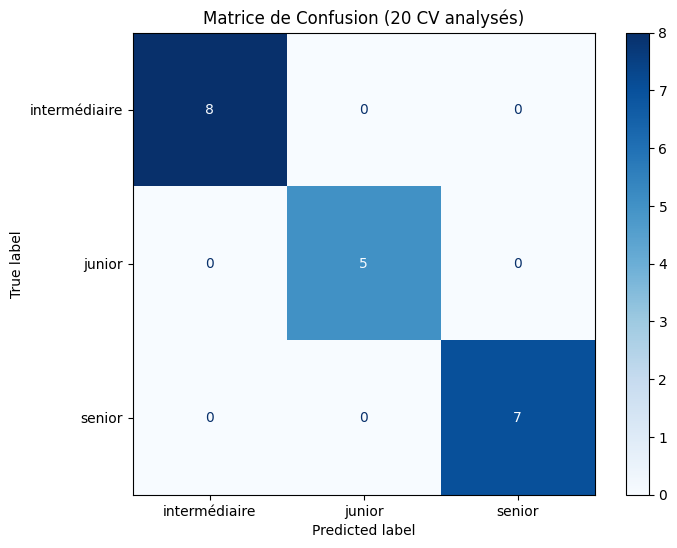

In [23]:



X = []
y_text = []


cv_nodes = [n for n, d in G.nodes(data=True) if d.get('type') == 'CV']

for n in cv_nodes:
    d = G.nodes[n]

    emb = model.encode(d['text'])

    graph_feats = [
        G.degree(n),
        d.get('community_global', 0),
        d.get('internal_density', 0)
    ]

    X.append(np.concatenate([emb, graph_feats]))
    y_text.append(d['label'])

X = np.array(X)
y_text = np.array(y_text)


le = LabelEncoder()
y_encoded = le.fit_transform(y_text)


clf = RandomForestClassifier(random_state=42)
clf.fit(X, y_encoded)
predictions_encoded = clf.predict(X)


print("\n--- Évaluation Détaillée (Dataset Complet) ---")
y_true_names = le.inverse_transform(y_encoded)
y_pred_names = le.inverse_transform(predictions_encoded)

print(classification_report(y_true_names, y_pred_names, target_names=le.classes_))


cm = confusion_matrix(y_true_names, y_pred_names, labels=le.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title(f"Matrice de Confusion ({len(cv_nodes)} CV analysés)")
plt.show()

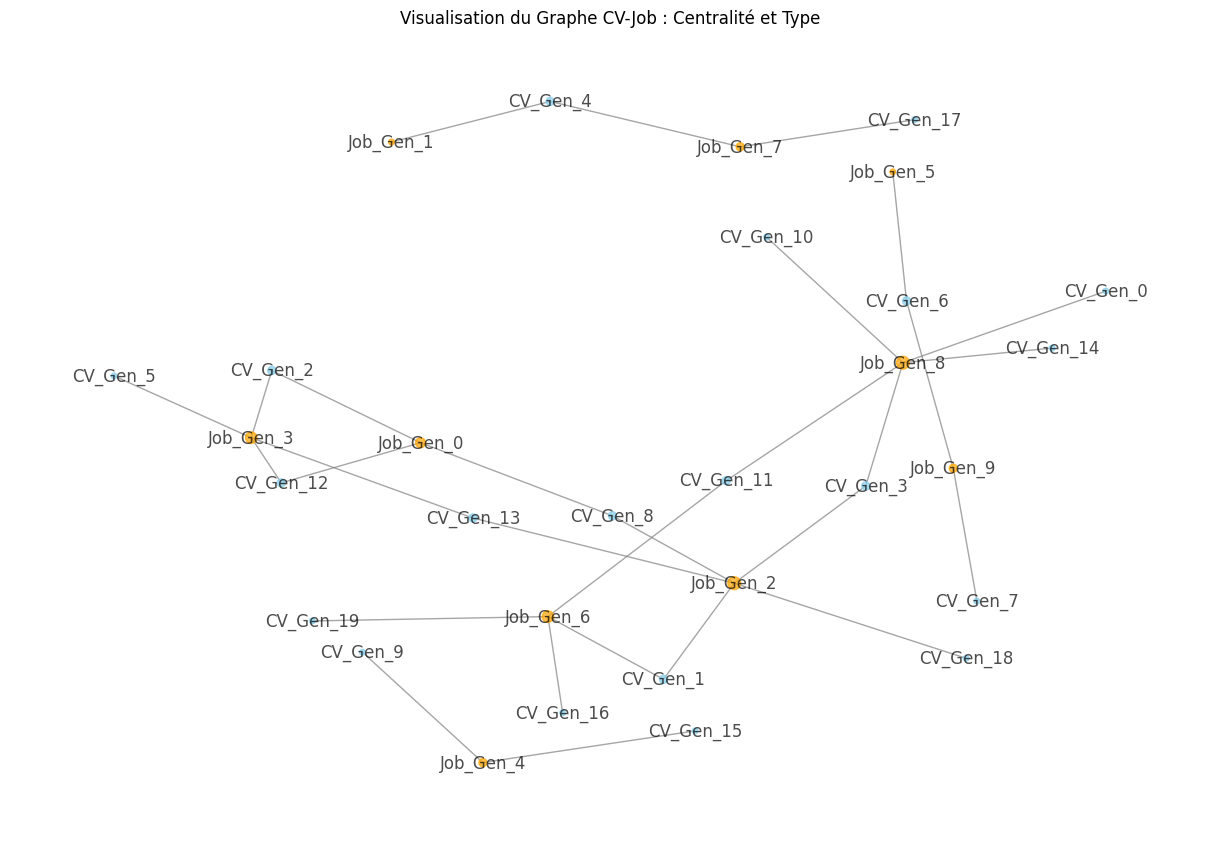

In [24]:
def plot_bipartite_communities(graph):
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(graph, k=0.5)


    colors = ['skyblue' if graph.nodes[n]['type'] == 'CV' else 'orange' for n in graph.nodes()]


    node_sizes = [v * 500 for v in nx.degree_centrality(graph).values()]

    nx.draw(graph, pos, with_labels=True, node_color=colors,
            node_size=node_sizes, edge_color='gray', alpha=0.7)

    plt.title("Visualisation du Graphe CV-Job : Centralité et Type")
    plt.show()

plot_bipartite_communities(G)

--- Analyse des Profils Atypiques (Outliers) ---

Nombre de profils polyvalents détectés : 4

ID du CV : CV_Gen_1
Score de polyvalence (Betweenness) : 0.0813
Extrait du profil : Content Strategy, Copywriting, Social Media, SEO, Ads. intermédiaire....

ID du CV : CV_Gen_3
Score de polyvalence (Betweenness) : 0.1047
Extrait du profil : SEO, Copywriting, Content Strategy, Social Media, Ads. intermédiaire....

ID du CV : CV_Gen_8
Score de polyvalence (Betweenness) : 0.0599
Extrait du profil : Pandas, Deep Learning, SQL, Scikit-learn. intermédiaire....

ID du CV : CV_Gen_13
Score de polyvalence (Betweenness) : 0.0903
Extrait du profil : Social Media, Copywriting, SEO. intermédiaire....


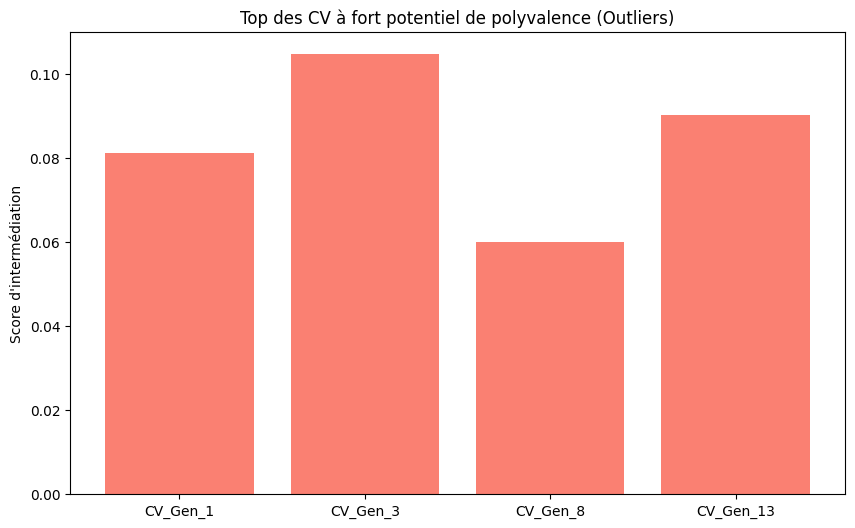

In [25]:



print("--- Analyse des Profils Atypiques (Outliers) ---")

betweenness = nx.betweenness_centrality(G)

bet_values = [v for n, v in betweenness.items() if G.nodes[n]['type'] == 'CV']
threshold = np.mean(bet_values) + np.std(bet_values)

outliers = []
for n, score in betweenness.items():
    if G.nodes[n]['type'] == 'CV' and score > threshold:
        outliers.append((n, score, G.nodes[n].get('text', 'N/A')))


if not outliers:
    outliers = sorted([(n, betweenness[n], G.nodes[n]['text'])
                       for n in G.nodes if G.nodes[n]['type'] == 'CV'],
                      key=lambda x: x[1], reverse=True)[:2]

print(f"\nNombre de profils polyvalents détectés : {len(outliers)}")
for name, score, text in outliers:
    print(f"\nID du CV : {name}")
    print(f"Score de polyvalence (Betweenness) : {score:.4f}")
    print(f"Extrait du profil : {text[:150]}...")


plt.figure(figsize=(10, 6))
plt.bar([str(x[0]) for x in outliers], [x[1] for x in outliers], color='salmon')
plt.title("Top des CV à fort potentiel de polyvalence (Outliers)")
plt.ylabel("Score d'intermédiation")
plt.show()